# Parte 2: Evaluación, extracción estructurada y comparación de modelos

**Pregunta guía:** ¿Pueden convertir documentos escaneados y entrevistas en audio en un archivo de texto estructurado y buscable?

**Insumos:** `datos/documentos.csv` y `datos/transcripciones.csv` de la Parte 1, la muestra de evaluación definida en `datos/muestra_evaluacion.json` y las transcripciones manuales de `datos/referencias/`.

## Reglas de evaluación (fijadas antes de ver métricas)

- **Muestra:** 10 documentos y 10 clips del corpus de la Parte 1. No se recolectó ningún dato nuevo. La misma muestra se usa para todos los modelos.
- **Documentos (4 impresos, 3 fotos, 3 manuscritos):** de cada uno se evalúa un **recorte fijo** de 5 a 15 líneas, guardado en `datos/raw/documentos/recortes/`. Sus coordenadas están en el JSON de la muestra. El estudiante transcribió a mano cada recorte respetando la ortografía original. Los manuscritos de 1544 y 1677 quedaron fuera porque su paleografía no se puede transcribir con fiabilidad sin formación especializada. Se analizan aparte como casos difíciles.
- **Clips (8 de OpenSLR 73 + 2 entrevistas):**
  - Los 8 clips de OpenSLR (4 voces femeninas y 4 masculinas) se eligieron al azar con la semilla 2026. Su referencia es el **guion humano** que publica el propio corpus (`line_index_*.tsv`), unido en el orden de `manifest_clips.csv`. Es la transcripción humana oficial del corpus: el texto que cada hablante leyó en voz alta. No se volvió a verificar al oído.
  - En las 2 entrevistas, el estudiante transcribió a mano los **primeros 60 s** de cada una, y en ellas se evalúa solo esa ventana.
- **Normalización (igual para referencia e hipótesis):** `voz.normalizar` de la Sesión 13, que pasa a minúsculas, quita la puntuación y conserva las tildes. Antes se quitan las marcas `[HABLANTE_n]`, los `[?]` de lo ilegible y las muletillas (eh, eeeh, ah, aaah, mmm), que la referencia manual sí registra pero no son contenido. Es el mismo criterio del normalizador de Whisper. Los nombres seudonimizados se reemplazan igual en ambos lados.
- **Métricas:**
  - CER (documentos) y WER (audio), calculadas con `jiwer`.
  - **Latencia:** segundos por documento, y en audio el factor de tiempo real (segundos de proceso ÷ segundos de audio).
  - Todo se midió en la misma laptop, en CPU con 2 núcleos.
- **Configuraciones:** son las de la Parte 1 para la línea base, y las de cada librería por defecto para los modelos alternativos. **No se ajustó ningún parámetro mirando los resultados.**

In [1]:
# PROCESO 0: Rutas, versiones y datos de la Parte 1.
# Insumo: CSV de la Parte 1 y la definición de la muestra.
# Resultado: tablas `docs`, `clips` y el diccionario `muestra`.

# os: fija variables de entorno antes de cargar los modelos.
import os
# json: lee la muestra y guarda los resultados crudos.
import json
# re: limpia marcas que no son texto leído ni hablado.
import re
# time: mide la latencia de cada modelo.
import time
# sys: versión de Python.
import sys
# importlib.metadata: versión de cada paquete.
from importlib.metadata import version
# pathlib: rutas portables.
from pathlib import Path
# pandas: tablas de resultados.
import pandas as pd
# IPython.display: muestra tablas e imágenes dentro del notebook.
from IPython.display import display, Image as ImagenPNG
# voz (Sesión 13): carga de audio, normalización, CER/WER y seudonimización.
import voz

os.environ.setdefault("PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK", "True")
pd.set_option("display.max_colwidth", 120)
BASE = Path.cwd()
DATOS, RAW = BASE / "datos", BASE / "datos" / "raw"
EVAL = RAW / "eval"
EVAL.mkdir(parents=True, exist_ok=True)
print("Python", sys.version.split()[0], "|", {p: version(p) for p in ["paddleocr", "easyocr", "faster-whisper", "transformers", "torch", "jiwer"]})

docs = pd.read_csv(DATOS / "documentos.csv", keep_default_na=False)
clips = pd.read_csv(DATOS / "transcripciones.csv", keep_default_na=False)
muestra = json.loads((DATOS / "muestra_evaluacion.json").read_text(encoding="utf-8"))
DOCS_EVAL, CLIPS_EVAL = list(muestra["documentos"]), list(muestra["clips"])
print("Documentos de evaluación:", docs.set_index("id").loc[DOCS_EVAL, "tipo"].value_counts().to_dict())
print("Clips de evaluación:", clips.set_index("id").loc[CLIPS_EVAL, "origen"].value_counts().to_dict())

Python 3.12.15 | {'paddleocr': '3.7.0', 'easyocr': '1.7.2', 'faster-whisper': '1.2.1', 'transformers': '5.20.1', 'torch': '2.14.1+cpu', 'jiwer': '4.0.0'}
Documentos de evaluación: {'impreso': 4, 'foto': 3, 'manuscrito': 3}
Clips de evaluación: {'OpenSLR 73': 8, 'Entrevista UNMSM (Commons)': 2}


## Proceso 1. Muestra de evaluación y referencias manuales

In [2]:
# PROCESO 1: Cargar las referencias manuales y el guion humano de OpenSLR.
# Insumo: datos/referencias/*.txt, line_index_*.tsv y manifest_clips.csv.
# Resultado: diccionarios ref_doc (10) y ref_clip (10) con el texto de referencia seudonimizado.
ruta_seud = RAW / "seudonimos.json"
SEUDONIMOS = json.loads(ruta_seud.read_text(encoding="utf-8")) if ruta_seud.exists() else {}
REFS = DATOS / "referencias"


def leer_ref(id_):
    """datos/referencias/<id>.txt → texto manual sin espacios sobrantes (error si está vacío)."""
    texto = (REFS / f"{id_}.txt").read_text(encoding="utf-8").strip()
    assert texto, f"Falta la transcripción manual de {id_}"
    return texto


guion = {}
for genero in ["female", "male"]:
    tsv = pd.read_csv(RAW / "audio" / "openslr73_meta" / f"line_index_{genero}.tsv", sep="\t", header=None,
                      names=["archivo", "texto"], quoting=3)
    guion |= dict(zip(tsv["archivo"], tsv["texto"]))
manifiesto = pd.read_csv(RAW / "manifest_clips.csv").set_index("clip_id")

ref_doc = {i: leer_ref(i) for i in DOCS_EVAL}
ref_clip = {}
for c in CLIPS_EVAL:
    if muestra["clips"][c]["ventana_seg"]:            # entrevista: transcripción manual de la ventana
        ref_clip[c] = voz.seudonimizar(leer_ref(c), SEUDONIMOS) if SEUDONIMOS else leer_ref(c)
    else:                                             # OpenSLR: guion humano de cada enunciado, en orden
        wavs = manifiesto.loc[c, "wavs"].split(";")
        ref_clip[c] = " ".join(guion[w.removesuffix(".wav")] for w in wavs)

resumen_refs = pd.DataFrame(
    [{"id": i, "modalidad": "documento", "tipo": docs.set_index("id").loc[i, "tipo"], "palabras_ref": len(t.split()),
      "caracteres_ref": len(t), "origen_ref": "transcripción manual del recorte"} for i, t in ref_doc.items()] +
    [{"id": c, "modalidad": "audio", "tipo": clips.set_index("id").loc[c, "origen"], "palabras_ref": len(t.split()),
      "caracteres_ref": len(t), "origen_ref": "manual (0–60 s)" if muestra["clips"][c]["ventana_seg"] else "guion humano OpenSLR 73"}
     for c, t in ref_clip.items()])
resumen_refs

,id,modalidad,tipo,palabras_ref,caracteres_ref,origen_ref
0,doc_005,documento,impreso,43,295,transcripción manual del recorte
1,doc_006,documento,impreso,29,188,transcripción manual del recorte
2,doc_007,documento,impreso,49,299,transcripción manual del recorte
3,doc_008,documento,impreso,24,135,transcripción manual del recorte
4,doc_009,documento,foto,74,397,transcripción manual del recorte
5,doc_012,documento,foto,22,145,transcripción manual del recorte
6,doc_013,documento,foto,49,290,transcripción manual del recorte
7,doc_017,documento,manuscrito,34,174,transcripción manual del recorte
8,doc_019,documento,manuscrito,59,381,transcripción manual del recorte
9,doc_025,documento,manuscrito,25,141,transcripción manual del recorte


doc_007 | impreso | referencia: Maldonado, 4 de julio de 1914.  Señor Don Ricardo Palma,   Lima.  Muy distinguido señor y respetado amigo:  Siento inmen ...


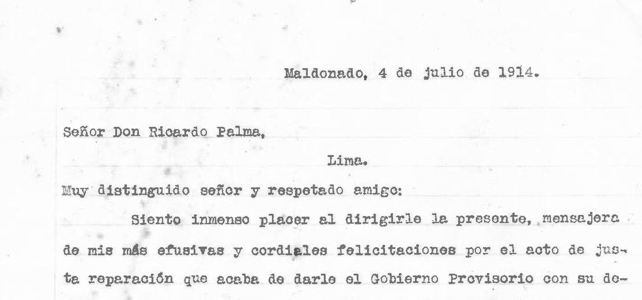

doc_013 | foto | referencia: PISAGUA, JUNIO 2 DE 1879.  SEÑORA CARMELA CARVAJAL DE PRAT  DIGNISIMA SEÑORA: "UN SAGRADO DEBER ME AUTORIZA A DIRIGIRME  ...


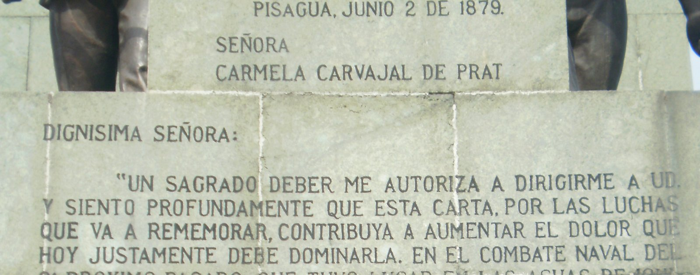

doc_019 | manuscrito | referencia: Lima, Agosto 10 de 1897  Sr J.M. Rodriguez R. Prefecto del Depto. [?] Lambayeque Mi querido Sr Prefecto:  El Sr Pedro Ad ...


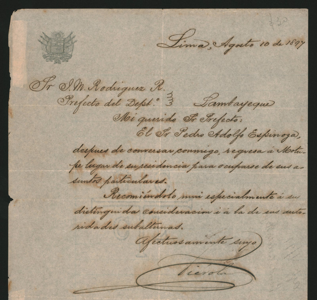

In [3]:
# PROCESO 1.1: Vista de los recortes que se evalúan (lo que el OCR y la persona leyeron).
# Insumo: datos/referencias/<id>_recorte.jpg.
# Resultado: miniaturas de 3 recortes, uno por tipo.

# PIL (Pillow): abre y reduce las imágenes.
from PIL import Image, ImageOps
Image.MAX_IMAGE_PIXELS = None
for i in ["doc_007", "doc_013", "doc_019"]:
    print(i, "|", docs.set_index("id").loc[i, "tipo"], "| referencia:", ref_doc[i][:120].replace("\n", " "), "...")
    im = Image.open(REFS / f"{i}_recorte.jpg"); im.thumbnail((700, 300)); display(im)

## Proceso 2. Normalización y funciones de medida

In [4]:
# PROCESO 2: Normalizar igual referencia e hipótesis y medir CER/WER por caso.
# Insumo: textos crudos.
# Resultado: funciones `limpiar`, `cer_caso` y `wer_caso`.


MULETILLAS = r"\b(?:e{2,}h*|e+h+|a{2,}h*|a+h+|m{2,}h*|e+m+)\b"  # eh, eeeh, ah, aaah, mmm, em (no toca "a" ni "e")


def limpiar(texto):
    """texto → sin [HABLANTE_n], [?] ni muletillas (no son contenido leído o dicho); el resto lo normaliza voz.normalizar."""
    texto = re.sub(r"\[HABLANTE_\d+\]|\[\?\]", " ", texto or "")
    return re.sub(MULETILLAS, " ", texto, flags=re.I)


def cer_caso(ref, hip):
    """(referencia, hipótesis) → CER normalizado de un documento."""
    return round(voz.cer([limpiar(ref)], [limpiar(hip)]), 4)


def wer_caso(ref, hip):
    """(referencia, hipótesis) → WER normalizado de un clip."""
    return round(voz.wer([limpiar(ref)], [limpiar(hip)]), 4)


print("Ejemplo de normalización:", repr(voz.normalizar(limpiar("[HABLANTE_1] Eeeeh... ¡Señor Don Ricardo Palma, [?] a Lima, ¿ah?!"))))

Ejemplo de normalización: 'señor don ricardo palma a lima'


## Proceso 3. Línea base sin ajuste: PaddleOCR y faster-whisper `small`

Se usa la misma configuración de la Parte 1 sobre los recortes y los clips de la muestra. Cada resultado se guarda en `datos/raw/eval/` con su tiempo de proceso.

In [5]:
# PROCESO 3: Línea base OCR, PaddleOCR (mobile) sobre los 10 recortes.
# Insumo: datos/raw/documentos/recortes/<id>_recorte.jpg.
# Resultado: texto, CER y segundos por documento.

# paddleocr: modelos PP-OCRv5 de detección y reconocimiento.
import paddleocr
from paddleocr import PaddleOCR

CONFIG_OCR = dict(device="cpu", enable_mkldnn=False, cpu_threads=2,
                  use_doc_orientation_classify=True, use_doc_unwarping=False, use_textline_orientation=True,
                  text_detection_model_name="PP-OCRv5_mobile_det", text_recognition_model_name="latin_PP-OCRv5_mobile_rec")
RECORTES = RAW / "documentos" / "recortes"


def preparar(id_):
    """recorte original → copia RGB con lado mayor ≤ 2000 px (mismo preprocesamiento de la Parte 1)."""
    destino = EVAL / "recortes_2000" / f"{id_}.jpg"
    destino.parent.mkdir(exist_ok=True)
    if not destino.exists():
        im = ImageOps.exif_transpose(Image.open(RECORTES / f"{id_}_recorte.jpg")).convert("RGB")
        im.thumbnail((2000, 2000)); im.save(destino, quality=95)
    return destino


def con_cache(modelo, id_, funcion):
    """(modelo, id, función que devuelve dict) → dict guardado en datos/raw/eval/<modelo>/<id>.json."""
    archivo = EVAL / modelo / f"{id_}.json"
    if archivo.exists():
        return json.loads(archivo.read_text(encoding="utf-8"))
    archivo.parent.mkdir(exist_ok=True)
    r = funcion()
    archivo.write_text(json.dumps(r, ensure_ascii=False), encoding="utf-8")
    return r


_paddle = {}


def ocr_paddle(id_):
    """id → {'texto', 'segundos'} con PaddleOCR."""
    if not _paddle:
        _paddle["m"] = PaddleOCR(**CONFIG_OCR)
    t0 = time.perf_counter()
    res = _paddle["m"].predict(str(preparar(id_)))
    return {"texto": " ".join(t for r in res for t in r["rec_texts"]), "segundos": round(time.perf_counter() - t0, 2)}


filas_ocr = []
for i in DOCS_EVAL:
    r = con_cache("paddleocr_mobile", i, lambda: ocr_paddle(i))
    filas_ocr.append({"id": i, "modelo": "PaddleOCR 3.7 PP-OCRv5 mobile (línea base)", "texto": r["texto"],
                      "segundos": r["segundos"], "cer": cer_caso(ref_doc[i], r["texto"])})
print(f"CER línea base PaddleOCR (10 docs, agregado): {voz.cer([limpiar(ref_doc[i]) for i in DOCS_EVAL], [limpiar(f['texto']) for f in filas_ocr]):.3f}")

C:\Users\Diego Sime\.conda\envs\pucp\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CER línea base PaddleOCR (10 docs, agregado): 0.228


In [6]:
# PROCESO 3.1: Línea base ASR, faster-whisper small + VAD sobre los 10 clips.
# Insumo: WAV de la muestra (las entrevistas solo de 0 a 60 s).
# Resultado: texto, WER, segundos y factor de tiempo real por clip.

# faster_whisper: Whisper en CTranslate2 (int8 en CPU).
from faster_whisper import WhisperModel

_whisper = {}


def audio_muestra(c):
    """id de clip → arreglo 16 kHz (recortado a la ventana manual si es entrevista)."""
    audio = voz.cargar_audio(BASE / clips.set_index("id").loc[c, "archivo_audio"])
    v = muestra["clips"][c]["ventana_seg"]
    return audio[int(v[0] * voz.SR):int(v[1] * voz.SR)] if v else audio


def asr_whisper_small(c):
    """id → {'texto', 'segundos', 'duracion'} con faster-whisper small (misma configuración de la Parte 1)."""
    if not _whisper:
        _whisper["m"] = WhisperModel("small", device="cpu", compute_type="int8", cpu_threads=2)
    audio = audio_muestra(c)
    t0 = time.perf_counter()
    segs, _ = _whisper["m"].transcribe(audio, language="es", beam_size=5, vad_filter=True,
                                       vad_parameters={"min_silence_duration_ms": 300})
    texto = " ".join(s.text.strip() for s in segs)
    return {"texto": texto, "segundos": round(time.perf_counter() - t0, 2), "duracion": round(len(audio) / voz.SR, 2)}


def seud(c, texto):
    """Seudonimiza con el diccionario privado solo las entrevistas (mismo trato que la referencia)."""
    return voz.seudonimizar(texto, SEUDONIMOS) if (SEUDONIMOS and muestra["clips"][c]["ventana_seg"]) else texto


filas_asr = []
for c in CLIPS_EVAL:
    r = con_cache("whisper_small", c, lambda: asr_whisper_small(c))
    hip = seud(c, r["texto"])
    filas_asr.append({"id": c, "modelo": "faster-whisper small (línea base)", "texto": hip, "segundos": r["segundos"],
                      "duracion": r["duracion"], "rtf": round(r["segundos"] / r["duracion"], 3), "wer": wer_caso(ref_clip[c], hip)})
print(f"WER línea base whisper small (10 clips, agregado): {voz.wer([limpiar(ref_clip[c]) for c in CLIPS_EVAL], [limpiar(f['texto']) for f in filas_asr]):.3f}")

WER línea base whisper small (10 clips, agregado): 0.065


## Proceso 4. Modelos alternativos sobre las mismas muestras

**Documentos: EasyOCR 1.7 (`es`, CPU).** Usa otra arquitectura que PaddleOCR (detector CRAFT y reconocedor CRNN, en PyTorch), se instala solo con pip, sin binarios del sistema, y trae un modelo latino con tildes y ñ. Así sirve como contraste real frente a PP-OCRv5. Tesseract quedó descartado porque exigía instalar un ejecutable del sistema y datos de idioma.

**Audio: NVIDIA Parakeet TDT 0.6B v3** (25 idiomas europeos, incluido el español), usado con `voz.Transcriptor` de la Sesión 13. Es un transductor, no un modelo de lenguaje generativo, así que no "inventa" texto en los silencios. Es el más rápido del catálogo de la sesión en CPU. Se le pasan los mismos tramos de voz del VAD Silero.

In [7]:
# PROCESO 4: OCR alternativo, EasyOCR sobre los mismos 10 recortes.
# Insumo: los mismos recortes preprocesados.
# Resultado: texto, CER y segundos por documento.

# torch: limitar los hilos de CPU de EasyOCR.
import torch
# easyocr: detector CRAFT + reconocedor CRNN (PyTorch).
import easyocr

torch.set_num_threads(2)
_easy = {}


def ocr_easy(id_):
    """id → {'texto', 'segundos'} con EasyOCR (lectura por líneas, sin párrafos)."""
    if not _easy:
        _easy["m"] = easyocr.Reader(["es"], gpu=False, verbose=False)
    t0 = time.perf_counter()
    lineas = _easy["m"].readtext(str(preparar(id_)), detail=0, paragraph=False)
    return {"texto": " ".join(lineas), "segundos": round(time.perf_counter() - t0, 2)}


for i in DOCS_EVAL:
    r = con_cache("easyocr", i, lambda: ocr_easy(i))
    filas_ocr.append({"id": i, "modelo": "EasyOCR 1.7 (es)", "texto": r["texto"], "segundos": r["segundos"],
                      "cer": cer_caso(ref_doc[i], r["texto"])})
print(f"CER EasyOCR (10 docs, agregado): {voz.cer([limpiar(ref_doc[i]) for i in DOCS_EVAL], [limpiar(f['texto']) for f in filas_ocr if f['modelo'].startswith('EasyOCR')]):.3f}")

CER EasyOCR (10 docs, agregado): 0.334


In [8]:
# PROCESO 4.1: ASR alternativo, Parakeet TDT 0.6B v3 sobre los mismos 10 clips.
# Insumo: los mismos audios (y ventanas).
# Resultado: texto, WER, segundos y factor de tiempo real por clip.
_parakeet = {}


def asr_parakeet(c):
    """id → {'texto', 'segundos', 'duracion'} con Parakeet v3 (tramos VAD de voz.Transcriptor)."""
    if not _parakeet:
        _parakeet["m"] = voz.Transcriptor("parakeet-v3", device="cpu")
    audio = audio_muestra(c)
    t0 = time.perf_counter()
    texto = " ".join(s.texto for s in _parakeet["m"].segmentos(audio))
    return {"texto": texto, "segundos": round(time.perf_counter() - t0, 2), "duracion": round(len(audio) / voz.SR, 2)}


for c in CLIPS_EVAL:
    r = con_cache("parakeet_v3", c, lambda: asr_parakeet(c))
    hip = seud(c, r["texto"])
    filas_asr.append({"id": c, "modelo": "Parakeet TDT 0.6B v3", "texto": hip, "segundos": r["segundos"], "duracion": r["duracion"],
                      "rtf": round(r["segundos"] / r["duracion"], 3), "wer": wer_caso(ref_clip[c], hip)})
print(f"WER Parakeet v3 (10 clips, agregado): {voz.wer([limpiar(ref_clip[c]) for c in CLIPS_EVAL], [limpiar(f['texto']) for f in filas_asr if f['modelo'].startswith('Parakeet')]):.3f}")

WER Parakeet v3 (10 clips, agregado): 0.052


In [9]:
# PROCESO 4.2: Resultados por caso de los cuatro modelos.
# Insumo: filas_ocr y filas_asr.
# Resultado: datos/evaluacion_modelos.csv (una fila por caso y modelo).
ev_ocr = pd.DataFrame(filas_ocr).merge(docs[["id", "tipo"]], on="id")
ev_asr = pd.DataFrame(filas_asr).merge(clips[["id", "origen"]].rename(columns={"origen": "tipo"}), on="id")
ev_ocr["referencia"] = ev_ocr["id"].map(ref_doc)
ev_asr["referencia"] = ev_asr["id"].map(ref_clip)
evaluacion = pd.concat([ev_ocr.assign(modalidad="documento", metrica="CER", valor=ev_ocr["cer"]),
                        ev_asr.assign(modalidad="audio", metrica="WER", valor=ev_asr["wer"])], ignore_index=True)
evaluacion = evaluacion[["id", "modalidad", "tipo", "modelo", "metrica", "valor", "segundos", "duracion", "rtf", "texto", "referencia"]]
evaluacion.to_csv(DATOS / "evaluacion_modelos.csv", index=False, encoding="utf-8")
display(ev_ocr.pivot(index=["id", "tipo"], columns="modelo", values="cer"))
display(ev_asr.pivot(index=["id", "tipo"], columns="modelo", values="wer"))

,modelo,EasyOCR 1.7 (es),PaddleOCR 3.7 PP-OCRv5 mobile (línea base)
id,tipo,,
doc_005,impreso,0.3500,0.4071
doc_006,impreso,0.1006,0.0112
doc_007,impreso,0.2098,0.4545
doc_008,impreso,0.3968,0.2778
doc_009,foto,0.1606,0.0233
doc_012,foto,0.1679,0.0153
doc_013,foto,0.0179,0.0072
doc_017,manuscrito,0.8182,0.6591
doc_019,manuscrito,0.6583,0.2000


,modelo,Parakeet TDT 0.6B v3,faster-whisper small (línea base)
id,tipo,,
clip_003,OpenSLR 73,0.0238,0.0397
clip_011,OpenSLR 73,0.0267,0.0321
clip_014,OpenSLR 73,0.0055,0.0387
clip_015,OpenSLR 73,0.0299,0.0359
clip_016,OpenSLR 73,0.0146,0.0365
clip_018,OpenSLR 73,0.0428,0.0428
clip_019,OpenSLR 73,0.0443,0.0570
clip_020,OpenSLR 73,0.0476,0.0340
clip_022,Entrevista UNMSM (Commons),0.2432,0.2432


## Proceso 5. Extracción estructurada con LLM

**Modelo:** `Qwen/Qwen2.5-1.5B-Instruct` en local (CPU, float32, greedy y 2 hilos), sin API ni claves. El prompt está versionado en `modelos/prompt_extraccion.json` y el código en `extraccion_llm.py`.

**Campos:**
- Siempre `modalidad`, `tema` y `resumen`.
- En documentos, `emisor`, `fecha` y `monto` **solo si aparecen**.
- En audios, `numero_hablantes` y `citas_clave`.
- Lo ausente va como `null`. Si el modelo agrega claves no pedidas, se descartan y se registran como "claves inventadas".

**Entrada:** el texto **seudonimizado** de la Parte 1, recortado a 1.500 caracteres.

In [10]:
# PROCESO 5: Extraer campos JSON de los 47 textos (25 OCR + 22 ASR).
# Insumo: texto_ocr y texto_asr seudonimizados.
# Resultado: datos/extraccion_llm.csv con id, modalidad, campos_json, modelo_llm y fecha.

# extraccion_llm: prompt, llamada al LLM local, lectura del JSON y caché por registro.
import extraccion_llm as ext

prompt = ext.cargar_prompt(BASE / "modelos" / "prompt_extraccion.json")
print("Mensaje de sistema:", prompt["sistema"], "\n")
print(ext.mensajes("<texto>", "documento", prompt)[1]["content"][:900])

registros = ([(i, t, "documento") for i, t in zip(docs["id"], docs["texto_ocr"])] +
             [(i, t, "audio") for i, t in zip(clips["id"], clips["texto_asr"])])
salidas = [ext.extraer(i, t, m, prompt, RAW / "llm") for i, t, m in registros]
extraccion = pd.DataFrame([{"id": s["id"], "modalidad": s["modalidad"],
                            "campos_json": json.dumps(s["campos"], ensure_ascii=False) if s["campos"] else None,
                            "modelo_llm": s["modelo_llm"], "fecha": s["fecha"], "json_valido": s["json_valido"],
                            "claves_inventadas": len(s["claves_inventadas"]), "segundos": s["segundos"]} for s in salidas])
extraccion.to_csv(DATOS / "extraccion_llm.csv", index=False, encoding="utf-8")
print(f"JSON válidos: {extraccion['json_valido'].sum()}/{len(extraccion)} | claves inventadas descartadas: {extraccion['claves_inventadas'].sum()} "
      f"| {extraccion['segundos'].mean():.0f} s por texto en CPU")
extraccion.head(6)

Mensaje de sistema: Eres un asistente de archivo que extrae datos de textos peruanos. Los textos vienen de OCR (documentos antiguos) o de reconocimiento de voz (audios) y pueden tener errores de lectura. Respondes solo con JSON válido. Nunca inventas datos: si algo no aparece en el texto, usas null. 

Lee el texto de un DOCUMENTO y completa:
- "modalidad": siempre "documento".
- "tema": de 2 a 6 palabras sobre de qué trata.
- "resumen": una oración de máximo 30 palabras, basada solo en el texto.
- "emisor": persona o institución que firma o emite el documento, solo si aparece escrita; si no, null.
- "fecha": la fecha tal como aparece escrita en el texto; si no aparece, null.
- "monto": una cantidad de dinero con su moneda, solo si aparece; si no, null.

Devuelve solo un objeto JSON con exactamente estas claves: "modalidad", "tema", "resumen", "emisor", "fecha", "monto".

TEXTO (documento):
"""
<texto>
"""
JSON válidos: 47/47 | claves inventadas descartadas: 0 | 53 s por texto en CPU


,id,modalidad,campos_json,modelo_llm,fecha,json_valido,claves_inventadas,segundos
0,doc_001,documento,"{""modalidad"": ""documento"", ""tema"": ""revistas latinoamericanas"", ""resumen"": ""La revista presenta sus nuevas medidas y...",Qwen/Qwen2.5-1.5B-Instruct,2026-10-25,True,0,43.7
1,doc_002,documento,"{""modalidad"": ""Documento"", ""tema"": ""Revuelta militar en Lima"", ""resumen"": ""Se describe una revuelta militar en Lima ...",Qwen/Qwen2.5-1.5B-Instruct,2026-10-25,True,0,48.0
2,doc_003,documento,"{""modalidad"": ""documento"", ""tema"": ""Manifestaciones políticas en Ecuador frente a la Paz Americana"", ""resumen"": ""El ...",Qwen/Qwen2.5-1.5B-Instruct,2026-10-25,True,0,56.2
3,doc_004,documento,"{""modalidad"": ""documento"", ""tema"": ""Comercio entre Perú y Estados Unidos"", ""resumen"": ""El Diario Comercial presenta ...",Qwen/Qwen2.5-1.5B-Instruct,2026-10-25,True,0,51.8
4,doc_005,documento,"{""modalidad"": ""documento"", ""tema"": ""Constitución Perú"", ""resumen"": ""La Constitución establece que la Nación es la as...",Qwen/Qwen2.5-1.5B-Instruct,2026-10-25,True,0,38.4
5,doc_006,documento,"{""modalidad"": ""documento"", ""tema"": ""Constitución Política de la República Peruana"", ""resumen"": ""La Constitución Polí...",Qwen/Qwen2.5-1.5B-Instruct,2026-10-25,True,0,37.0


In [11]:
# PROCESO 5.1: ¿Cuántos campos opcionales quedaron en null? (no inventar es preferible a rellenar).
# Insumo: campos_json.
# Resultado: proporción de null por campo y modalidad.
campos = pd.json_normalize([json.loads(c) if c else {} for c in extraccion["campos_json"]]).assign(modalidad=extraccion["modalidad"])
(campos.isna().groupby(campos["modalidad"]).mean().round(2)
 [["emisor", "fecha", "monto", "numero_hablantes", "citas_clave"]])

,emisor,fecha,monto,numero_hablantes,citas_clave
modalidad,,,,,
audio,1.00,1.0,1.00,0.0,0.0
documento,0.68,0.4,0.96,1.0,1.0


## Proceso 6. Auditoría humana de 20 extracciones

**Muestra:** 10 documentos y 10 audios elegidos al azar con la semilla 2026, antes de leer las extracciones.

**Criterio de "extracción completamente correcta":** se tienen que cumplir **todas** estas condiciones.
1. El JSON es válido y tiene las claves pedidas.
2. El `tema` y el `resumen` son fieles al texto. No agregan hechos que el texto no dice.
3. En documentos, `emisor`, `fecha` y `monto` coinciden con el texto cuando aparecen. Si no aparecen, van en `null`. Un dato inventado es un error.
4. En audios, `numero_hablantes` coincide con las marcas de hablante y las `citas_clave` están en la transcripción.

Cuando el texto OCR es ilegible, la extracción correcta es la que lo reconoce (resumen prudente y campos en `null`).

Se juzga contra el **texto de entrada que recibió el LLM** (OCR o ASR), no contra la imagen o el audio originales. Los errores de lectura ya se miden con el CER y el WER.

**Criterio adicional del revisor:** un valor como "no especificado" en lugar de `null` se aceptó como equivalente a `null`, porque tiene el mismo significado. Solo ocurrió en `doc_025`.

El estudiante revisó los 20 casos uno por uno, comparando cada campo con el texto de entrada. Sus veredictos (si/no y el motivo) están en `datos/auditoria_llm.csv`, en las columnas `correcto` y `comentario`.

In [12]:
# PROCESO 6: Auditoría humana (resultado de la revisión manual).
# Insumo: datos/auditoria_llm.csv completado a mano.
# Resultado: extracciones completamente correctas sobre 20 y ejemplos de error.
semilla = 2026
ids_auditoria = (extraccion[extraccion["modalidad"] == "documento"].sample(10, random_state=semilla)["id"].tolist() +
                 extraccion[extraccion["modalidad"] == "audio"].sample(10, random_state=semilla)["id"].tolist())
auditoria = pd.read_csv(DATOS / "auditoria_llm.csv", keep_default_na=False)
assert sorted(auditoria["id"]) == sorted(ids_auditoria), "La auditoría no corresponde a la muestra aleatoria"
auditoria["correcto"] = auditoria["correcto"].astype(str).str.strip().str.lower().isin(["1", "si", "sí", "true", "x"])
aciertos = int(auditoria["correcto"].sum())
print(f"Acuerdo LLM-Humano: {aciertos}/20 = {aciertos / 20:.0%}")
print(auditoria.groupby("modalidad")["correcto"].agg(["sum", "count"]))
auditoria.loc[~auditoria["correcto"], ["id", "modalidad", "comentario"]]

Acuerdo LLM-Humano: 7/20 = 35%
           sum  count
modalidad            
audio        4     10
documento    3     10


,id,modalidad,comentario
0,doc_004,documento,"tema dice comercio entre Perú y Estado Unidos, cuando en raelidad no se puede distinguir de qué se trata el texto."
1,doc_016,documento,"modalidad dice ""estado general"". No existe tal modalidad. Solo hay modalides: documento o audio"
2,doc_019,documento,"tema ""presidente"" no sustentado (viene de ""pesidencia"" = residencia); emisor incorrecto ""Fr Freeciente"" (confunde al..."
3,doc_017,documento,"tema no se puede extraer porque no es puede leer el contenido correctamente, tampoco el resumen"
7,doc_009,documento,resumen no conincide con el contenido. Felipe no le escribe a su esposo Juan. Felipe le escribe a su esposa.
8,doc_011,documento,"no se reconoce el texto, por lo que no se puede saber si el tema es cambio doctrinal"
9,doc_018,documento,no se distingue el texto como para poder reconocer el tema o el resumen
13,clip_015,audio,resumen no tiene sentido
14,clip_009,audio,"resumen solo tiene algunos temas, tema tambien solo aborda algunas cosas"
15,clip_023,audio,"cita_clave no literal (""creo"" en vez de ""créame""); resumen ""rico en educación"" no fiel"


**Lectura de la auditoría (7/20 = 35 % de extracciones completamente correctas).** Los 13 errores, agrupados a partir de los comentarios del revisor:

| Tipo de error | Casos | Ejemplo |
|---|---|---|
| Tema o resumen **inventado sobre OCR ilegible** | 4 (`doc_004`, `doc_011`, `doc_017`, `doc_018`) | "Comercio entre Perú y Estados Unidos" a partir de un texto de 1839 ilegible |
| Tema o resumen **incompleto o infiel** | 6 (`doc_009`, `clip_009`, `clip_011`, `clip_015`, `clip_016`, `clip_023`) | La carta de Salaverry a su esposa, resumida como dirigida "a su esposo Juan"; en `clip_016`, "tema no aborda todo" |
| Campo estructurado erróneo | 3 (`doc_016` modalidad, `doc_019` emisor, `clip_008` número de hablantes) | `numero_hablantes: 4` en un clip sin etiquetas de hablante |

En `clip_023`, además, una cita no es literal ("creo" en vez de "créame").

**Conclusiones:**
- Con 1.500 millones de parámetros, el LLM siempre devuelve un JSON válido (47/47) y nunca agrega claves que no se le pidieron.
- Pero **no sabe decir "no lo sé"**: ante un OCR ilegible prefiere inventar un tema antes que reconocer que no puede leerlo.
- En los clips de OpenSLR, que son frases leídas sin relación entre sí, fuerza un tema único.
- Para un archivo real conviene usar un modelo más grande, o filtrar antes los textos con confianza OCR menor que 0,5 para no enviarlos al LLM.

## Proceso 7. Casos difíciles

In [13]:
# PROCESO 7: Desempeño por tipo de documento y por tipo de audio.
# Insumo: evaluacion_modelos.csv.
# Resultado: CER medio por tipo de documento y WER medio por origen del audio, por modelo.
por_tipo = (evaluacion.groupby(["modalidad", "tipo", "modelo"])["valor"].mean().round(3)
            .unstack("modelo"))
por_tipo

modelo                                EasyOCR 1.7 (es)  \
modalidad tipo                                           
audio     Entrevista UNMSM (Commons)               NaN   
          OpenSLR 73                               NaN   
documento foto                                   0.115   
          impreso                                0.264   
          manuscrito                             0.763   

modelo                                PaddleOCR 3.7 PP-OCRv5 mobile (línea base)  \
modalidad tipo                                                                     
audio     Entrevista UNMSM (Commons)                                         NaN   
          OpenSLR 73                                                         NaN   
documento foto                                                             0.015   
          impreso                                                          0.288   
          manuscrito                                                       0.466   

modelo                                Parakeet TDT 0.6B v3  \
modalidad tipo                                               
audio     Entrevista UNMSM (Commons)                 0.173   
          OpenSLR 73                                 0.029   
documento foto                                         NaN   
          impreso                                      NaN   
          manuscrito                                   NaN   

modelo                                faster-whisper small (línea base)  
modalidad tipo                                                           
audio     Entrevista UNMSM (Commons)                              0.201  
          OpenSLR 73                                              0.040  
documento foto                                                      NaN  
          impreso                                                   NaN  
          manuscrito                                                NaN

In [14]:
# PROCESO 7.1: Peor documento y peor clip, comparando referencia e hipótesis.
# Insumo: evaluacion.
# Resultado: dos ejemplos de error explicados con el texto.
for metrica in ["CER", "WER"]:
    peor = evaluacion[evaluacion["metrica"] == metrica].sort_values("valor").iloc[-1]
    print(f"--- Peor caso {metrica}: {peor['id']} ({peor['tipo']}, {peor['modelo']}) = {peor['valor']:.2f}")
    print("REFERENCIA:", voz.normalizar(limpiar(peor["referencia"]))[:300])
    print("HIPÓTESIS :", voz.normalizar(limpiar(peor["texto"]))[:300], "\n")

--- Peor caso CER: doc_017 (manuscrito, EasyOCR 1.7 (es)) = 0.82
REFERENCIA: domingo tristan del 822 mi mejor amigo incluyo a original de lo han traido desde la de carabeli y el oficio del comandan te gonzales
HIPÓTESIS : 2 0989l u 1z t2 sa ucacncare e 2 9e 822 oeox 4 2 c 2 22g2z2ax y2e p8aax yaa 7 jcut 014a6 e ema mza f qvnigo m0lau0 an l 6 dedve lta 

--- Peor caso WER: clip_022 (Entrevista UNMSM (Commons), Parakeet TDT 0.6B v3) = 0.24
REFERENCIA: buenas noches soy persona_1 estudiante de la san marcos cuál es su nombre persona_2 señor persona_2 esta entrevista va a ser publicada en un foro de internet está de acuerdo ya está bien qué significa qué es el perú para usted el perú es mi patria es una patria donde han nacido mis ancestros he naci
HIPÓTESIS : buenas noches soy yanter persona_1 estudiante de la san marcos cuál es su nombre persona_2 señor persona_2 esta entrevista va a ser publicada en un foro de internet está de acuerdo ya está bien muy bien la primera pregunta es qué sig

In [15]:
# PROCESO 7.2: Manuscritos coloniales fuera de la muestra (1544 y 1677): ¿qué devuelve el OCR?
# Insumo: documentos.csv (OCR de la Parte 1).
# Resultado: confianza media y primeras líneas del OCR de los manuscritos más difíciles.
dificiles = docs[docs["id"].isin(["doc_020", "doc_022", "doc_023"])][["id", "titulo", "confianza_media", "n_caracteres", "texto_ocr"]].copy()
dificiles["texto_ocr"] = dificiles["texto_ocr"].str.replace("\n", " ").str[:160]
dificiles

,id,titulo,confianza_media,n_caracteres,texto_ocr
19,doc_020,AR-ANH-EF-Secc.II-20.jpg,0.472,1129,"ovi o E pa nee Ce de Cindad. Corforme alodi pue to por fumag poxsunzeal. Cedula fha enmaded, atrece refebrexo de..."
21,doc_022,AR-ANH-EF-Secc.II-2.pdf,0.483,324,50 00 S0so wts4ow8v 80201802700800300 e0 w842000n002600 04000600665000063.8wm 24y0188008t ytoucomormoreoen2...
22,doc_023,AR-ANH-EF-Secc.II-14-1.pdf,0.330,181,gal ma t aa m d a aa emmotncamiebalpoma tameen apor qede afmin s oo deroembre yreaaeracrdededa...


In [16]:
# PROCESO 7.3: Diagnóstico, ¿por qué PaddleOCR falla en dos impresos nítidos (doc_005 y doc_007)?
# Insumo: los mismos recortes evaluados.
# Resultado: ángulo que el clasificador de orientación asigna a cada línea (0 = derecha, 1 = girada 180°).
# Es solo para explicar el error: la configuración evaluada NO se cambia con este resultado.
if not _paddle:
    _paddle["m"] = PaddleOCR(**CONFIG_OCR)
for i in ["doc_007", "doc_005"]:
    r = _paddle["m"].predict(str(preparar(i)))[0]
    angulos = list(r["textline_orientation_angles"])
    print(f"{i}: {sum(angulos)} de {len(angulos)} líneas marcadas como giradas 180°")
    for t, a in list(zip(r["rec_texts"], angulos))[:7]:
        print(f"   ángulo={a}  {t[:70]}")

Creating model: ('PP-LCNet_x1_0_doc_ori', None, None)


Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\Diego Sime\.paddlex\official_models\PP-LCNet_x1_0_doc_ori`.


C:\Users\Diego Sime\.conda\envs\pucp\Lib\site-packages\paddle\utils\cpp_extension\extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
PLEASE USE OMP_NUM_THREADS WISELY.


Creating model: ('PP-LCNet_x1_0_textline_ori', None, None)


Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\Diego Sime\.paddlex\official_models\PP-LCNet_x1_0_textline_ori`.


...

Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\Diego Sime\.paddlex\official_models\PP-OCRv5_mobile_det`.


Creating model: ('latin_PP-OCRv5_mobile_rec', None, None)


Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\Diego Sime\.paddlex\official_models\latin_PP-OCRv5_mobile_rec`.


doc_007: 6 de 8 líneas marcadas como giradas 180°
   ángulo=1  -
   ángulo=1      
   ángulo=1  rrdrCo door
   ángulo=1  3WTT
   ángulo=1  eu edsd d deet c
   ángulo=1  Sa   a T T  
   ángulo=0  de mis más efusivas y cordiales felicitaciones por el aoto de jus-


doc_005: 6 de 15 líneas marcadas como giradas 180°
   ángulo=0  EL LIBERTADOR RAMON GASTILLA
   ángulo=0  GRAN MARISCAL DÉLOS EJERCITOS,
   ángulo=0  CONDECORADO-CON LAS MEDALLAS DE JUNIN,
   ángulo=0  AYACUCHO Y ANCAHS, Y PRESIDENTE
   ángulo=0  ALnA
   ángulo=0  RODOT
   ángulo=1  O  


### Lectura de los casos difíciles

**Documentos:**
- **Fotos (CER 0,015 con PaddleOCR):** fueron el mejor tipo, contra lo esperado. Las placas y portadas fotografiadas tienen letras grandes, en mayúsculas y con buen contraste, así que la inclinación no afectó a PP-OCRv5. EasyOCR sí sufrió más (0,115) con el relieve y los reflejos de las placas de bronce.
- **Impresos (0,29 Paddle; 0,26 EasyOCR):** el promedio esconde dos fallas puntuales de PaddleOCR.
  - En `doc_007` (carta mecanografiada) y `doc_005` (Constitución de 1856), el clasificador de orientación de línea marcó varias líneas como **giradas 180°**, las volteó y las leyó como basura ("rrdrCo door 3WTT…"). El diagnóstico del Proceso 7.3 lo muestra.
  - En la página completa (Parte 1) eso no ocurrió con `doc_007`: en un recorte, el clasificador pierde el contexto de la página.
  - `doc_005` además tiene **transparencia del reverso**: el texto de la otra cara se ve a través del papel y mete letras que no son de la página.
  - En los otros dos impresos, Paddle obtiene CER 0,011 (`doc_006`) y 0,278 (`doc_008`, carta mecanografiada que empieza con un "París, le" escrito a mano).
- **Manuscritos (0,47 Paddle; 0,76 EasyOCR):** son el peor caso, como era de esperar.
  - El manuscrito republicano más claro (Piérola, 1897) baja a CER 0,20, pero la cursiva de 1822 (`doc_017`) sube a 0,66.
  - Los dos modelos se entrenan sobre todo con texto impreso o de escena, no con cursiva histórica.
  - Fuera de la muestra, los manuscritos coloniales (1544, 1610 y 1677) devuelven texto sin sentido con confianza de 0,33 a 0,48. **Una confianza menor que 0,5 sirve como alarma** para mandar el documento a transcripción humana.

**Audio:**
- **Voz leída (OpenSLR):** el WER es muy bajo (0,029 Parakeet; 0,040 Whisper). Es habla clara, de un solo hablante, grabada con micrófono cercano y sin ruido.
- **Entrevistas:** el WER sube a 0,17–0,20. Son habla espontánea, con muletillas, autocorrecciones y frases cortadas ("en un sitio del ah… de América"). Los errores también cambian según el modelo. Whisper "limpia" el habla: omite el "¿me entiendes?" que sí está en la referencia. Parakeet transcribe más literal, pero confunde palabras ("poder Policial" por "poder judicial").
- En la diarización, `clip_022` sobresegmentó al entrevistado en dos hablantes, por un tramo de menos de 1 s.
- **No hubo audios con música.** El corpus no tiene ese caso y no se rellenó con material sintético. Para controlar las alucinaciones en los silencios se usó el VAD, y en la Parte 1 no aparecieron segmentos vacíos.
- **Quechua de Huaylas con MMS (bonificación opcional):** no se hizo.

## Proceso 8. Comparativa y decisión

In [17]:
# PROCESO 8: Tabla comparativa de modelos (misma muestra, misma máquina).
# Insumo: evaluacion.
# Resultado: datos/comparativa_modelos.csv y modelos/metricas.json para el dashboard.
TAMANO = {"PaddleOCR 3.7 PP-OCRv5 mobile (línea base)": "≈ 20 MB (det + rec mobile)",
          "EasyOCR 1.7 (es)": "≈ 95 MB (CRAFT + latin_g2)",
          "faster-whisper small (línea base)": "244 M parámetros (int8 ≈ 250 MB)",
          "Parakeet TDT 0.6B v3": "600 M parámetros (fp32 ≈ 2,4 GB)"}
agregado = []
for (modalidad, modelo), g in evaluacion.groupby(["modalidad", "modelo"]):
    refs, hips = [limpiar(r) for r in g["referencia"]], [limpiar(h) for h in g["texto"]]
    fila = {"modalidad": modalidad, "modelo": modelo, "casos": len(g), "tamano": TAMANO[modelo]}
    if modalidad == "documento":
        fila |= {"metrica": "CER", "valor": round(voz.cer(refs, hips), 3), "latencia": f"{g['segundos'].mean():.1f} s por recorte"}
    else:
        fila |= {"metrica": "WER", "valor": round(voz.wer(refs, hips), 3),
                 "latencia": f"RTF {g['segundos'].sum() / g['duracion'].sum():.2f}"}
    agregado.append(fila)
comparativa = pd.DataFrame(agregado).sort_values(["modalidad", "valor"])
comparativa.to_csv(DATOS / "comparativa_modelos.csv", index=False, encoding="utf-8")
comparativa

,modalidad,modelo,casos,tamano,metrica,valor,latencia
0,audio,Parakeet TDT 0.6B v3,10,"600 M parámetros (fp32 ≈ 2,4 GB)",WER,0.052,RTF 0.23
1,audio,faster-whisper small (línea base),10,244 M parámetros (int8 ≈ 250 MB),WER,0.065,RTF 0.29
3,documento,PaddleOCR 3.7 PP-OCRv5 mobile (línea base),10,≈ 20 MB (det + rec mobile),CER,0.228,9.2 s por recorte
2,documento,EasyOCR 1.7 (es),10,≈ 95 MB (CRAFT + latin_g2),CER,0.334,21.0 s por recorte


In [18]:
# PROCESO 8.1: Completar texto_referencia en los CSV de la Parte 1 y guardar las métricas finales.
# Insumo: ref_doc, ref_clip, comparativa y auditoría.
# Resultado: documentos.csv y transcripciones.csv con referencias + modelos/metricas.json.
docs["texto_referencia"] = docs["id"].map(ref_doc).fillna("")
docs["region_referencia"] = docs["id"].map(lambda i: json.dumps(muestra["documentos"][i]["recorte_relativo"]) if i in ref_doc else "")
clips["texto_referencia"] = clips["id"].map(ref_clip).fillna("")
clips["ventana_referencia_seg"] = clips["id"].map(lambda c: json.dumps(muestra["clips"][c]["ventana_seg"] or "completo") if c in ref_clip else "")
docs.to_csv(DATOS / "documentos.csv", index=False, encoding="utf-8")
clips.to_csv(DATOS / "transcripciones.csv", index=False, encoding="utf-8")

mejor = comparativa.loc[comparativa.groupby("modalidad")["valor"].idxmin()].set_index("modalidad")
metricas = {"cer": {r["modelo"]: r["valor"] for _, r in comparativa[comparativa["metrica"] == "CER"].iterrows()},
            "wer": {r["modelo"]: r["valor"] for _, r in comparativa[comparativa["metrica"] == "WER"].iterrows()},
            "acuerdo_llm_humano": aciertos, "auditados": 20}
(BASE / "modelos" / "metricas.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(metricas, ensure_ascii=False, indent=2))

{
  "cer": {
    "PaddleOCR 3.7 PP-OCRv5 mobile (línea base)": 0.228,
    "EasyOCR 1.7 (es)": 0.334
  },
  "wer": {
    "Parakeet TDT 0.6B v3": 0.052,
    "faster-whisper small (línea base)": 0.065
  },
  "acuerdo_llm_humano": 7,
  "auditados": 20
}


### Decisión para un entorno real

| Modalidad | Elegido | Por qué |
|---|---|---|
| Documentos | **PaddleOCR PP-OCRv5 mobile** | Tiene un CER 32 % menor que EasyOCR (0,228 frente a 0,334), es **2,3 veces más rápido** en CPU (9 s frente a 21 s por recorte) y sus modelos pesan una quinta parte. Gana con claridad en fotos y manuscritos. En impresos empata o pierde solo por el giro erróneo de líneas, que tiene arreglo (ver abajo). |
| Audio | **Parakeet TDT 0.6B v3** | Tiene un WER 20 % menor (0,052 frente a 0,065) y es **más rápido** en CPU (RTF 0,23 frente a 0,29). Mejora sobre todo en las entrevistas (0,173 frente a 0,201). Al no ser un modelo generativo, tampoco "inventa" texto en los silencios. Su costo es la memoria: 2,4 GB en fp32, contra unos 250 MB de Whisper `small` en int8. |

**Recomendaciones de operación** (no se aplicaron aquí para no ajustar nada con la muestra de evaluación):
1. En documentos escaneados derechos, desactivar la orientación por línea o validarla con la confianza.
2. Enviar a revisión humana todo documento con confianza media menor que 0,5, que en este corpus son los manuscritos coloniales.
3. Para un servidor modesto o un despliegue sin GPU con poca RAM, faster-whisper `small` en int8 sigue siendo la opción razonable: pierde solo 1,3 puntos de WER y cabe en cualquier máquina.

**Por tipo:**
- El mejor desempeño fue en **placas y portadas fotografiadas** (OCR) y en **voz leída de OpenSLR** (ASR).
- El peor fue en **manuscritos cursivos** y **entrevistas espontáneas en la calle**.
- La causa común es la distancia con los datos de entrenamiento: letra impresa moderna y habla leída o de medios, frente a paleografía del siglo XIX y conversación con ruido y muletillas.

In [19]:
# PROCESO 8.2: Resultados para el comentario de entrega (modelos elegidos, mismas 10 + 10 muestras).
wer_final = comparativa.set_index("modelo").loc["Parakeet TDT 0.6B v3", "valor"]
cer_final = comparativa.set_index("modelo").loc["PaddleOCR 3.7 PP-OCRv5 mobile (línea base)", "valor"]
print(f"Resultados Test: WER: {wer_final:.2f} | CER: {cer_final:.2f} | Acuerdo LLM-Humano: {aciertos}/20")

Resultados Test: WER: 0.05 | CER: 0.23 | Acuerdo LLM-Humano: 7/20
